#  Student Success Predictor

An end-to-end machine learning notebook that predicts whether a student **Passes** or **Fails** based on their study habits, attendance, and background — using your uploaded dataset (`data/student_performance_data.csv`).

**Pipeline:**
1. Import libraries
2. Load the dataset
3. Clean the data
4. Explore the data (EDA)
5. Preprocess / engineer the target
6. Train the model
7. Predict values
8. Plot & visualize results



## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                              confusion_matrix, roc_curve, roc_auc_score)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
np.random.seed(42)


## 2. Load the Dataset



In [2]:
df = pd.read_csv('../data/student_performance_data.csv')
print("Dataset shape:", df.shape)
df.head()


Dataset shape: (2392, 15)


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


In [4]:
df.describe()


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


## 3. Clean the Data

Check for missing values, duplicate rows, and drop columns that aren't useful as model features.

In [5]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())


Missing values per column:
StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64

Duplicate rows: 0


In [6]:
# Drop exact duplicate rows (if any)
df = df.drop_duplicates().reset_index(drop=True)

# StudentID is just an identifier, not a useful predictor
df = df.drop(columns=['StudentID'])

print("Shape after cleaning:", df.shape)


Shape after cleaning: (2392, 14)


## 4. Explore the Data

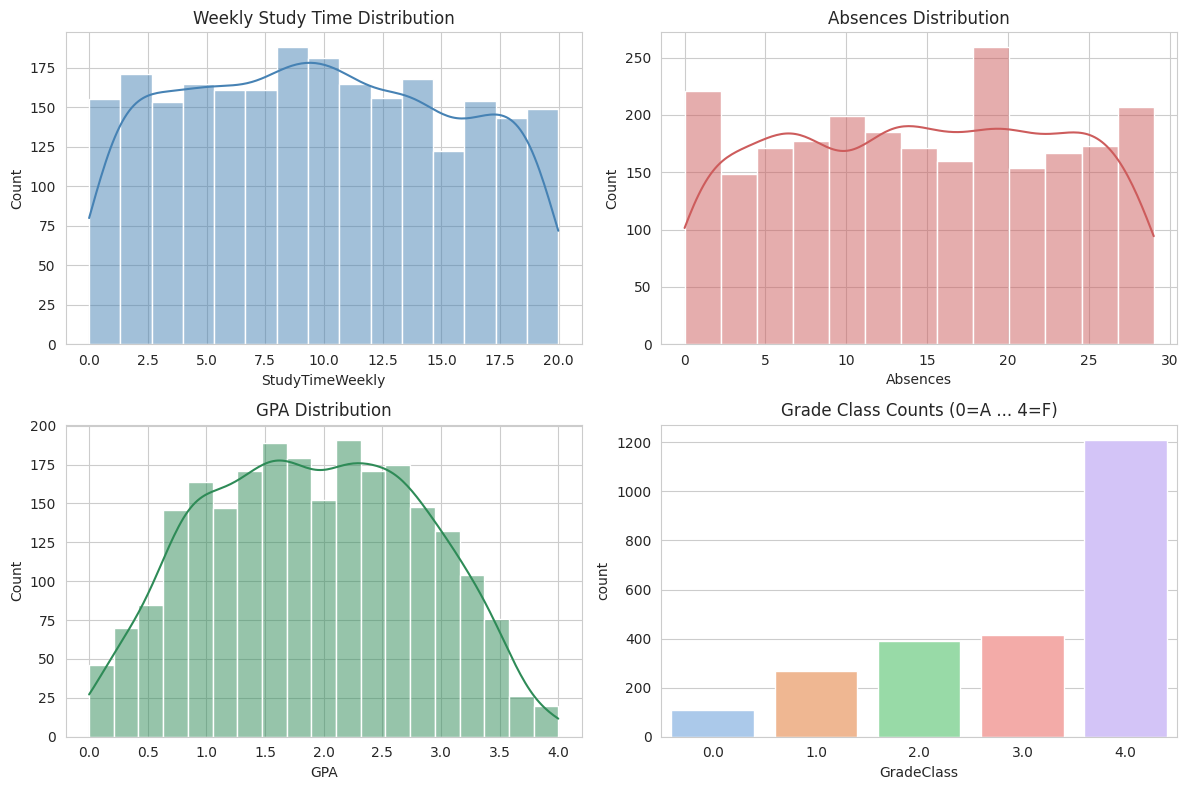

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(df['StudyTimeWeekly'], kde=True, ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('Weekly Study Time Distribution')

sns.histplot(df['Absences'], kde=True, ax=axes[0, 1], color='indianred')
axes[0, 1].set_title('Absences Distribution')

sns.histplot(df['GPA'], kde=True, ax=axes[1, 0], color='seagreen')
axes[1, 0].set_title('GPA Distribution')

sns.countplot(x='GradeClass', data=df, hue='GradeClass', palette='pastel', legend=False, ax=axes[1, 1])
axes[1, 1].set_title('Grade Class Counts (0=A ... 4=F)')

plt.tight_layout()
plt.show()


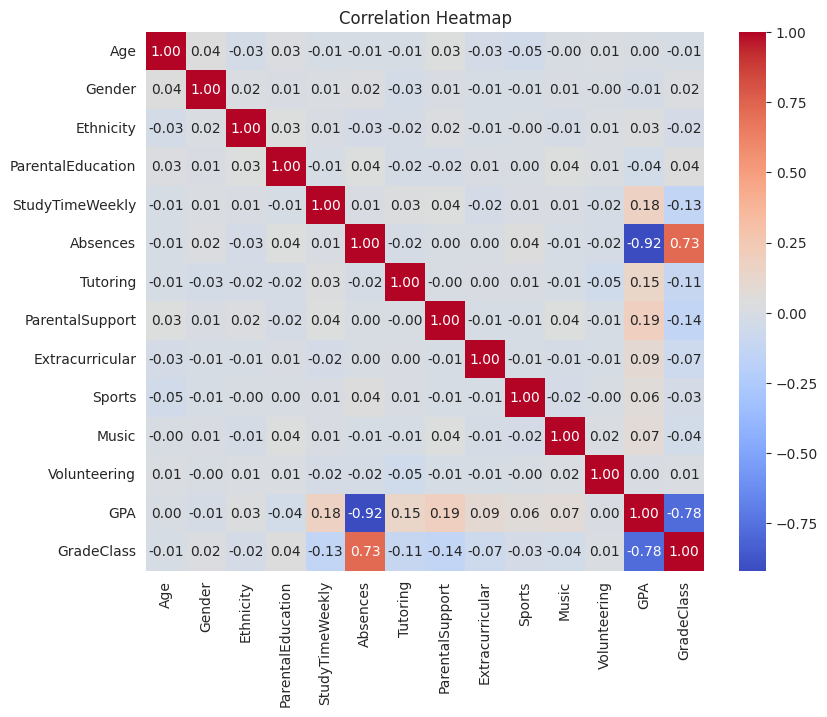

In [8]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()


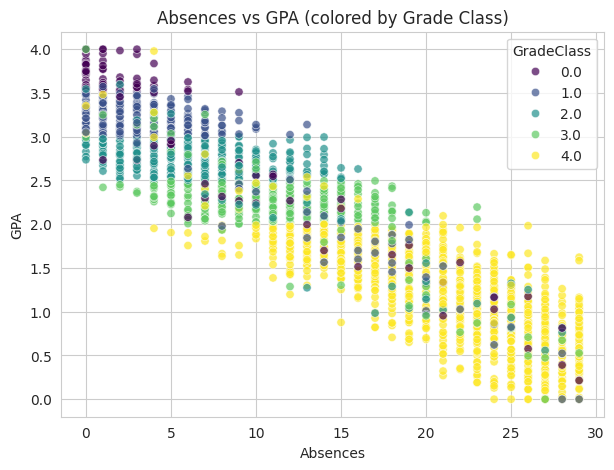

In [9]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x='Absences', y='GPA', hue='GradeClass', palette='viridis', data=df, alpha=0.7)
plt.title('Absences vs GPA (colored by Grade Class)')
plt.show()


## 5. Preprocess the Data

We turn this into a **binary success prediction** problem:

- `success = 1` → GradeClass is A, B, C, or D (passed)
- `success = 0` → GradeClass is F (failed)



In [10]:
df['success'] = (df['GradeClass'] < 4).astype(int)
print(df['success'].value_counts())


success
0    1211
1    1181
Name: count, dtype: int64


In [11]:
features = ['Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly',
            'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular',
            'Sports', 'Music', 'Volunteering']

X = df[features]
y = df['success']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train size:", X_train.shape, " Test size:", X_test.shape)


Train size: (1913, 12)  Test size: (479, 12)


## 6. Train the Model

Two models for comparison: **Logistic Regression** (baseline, uses scaled features) and **Random Forest** (handles non-linearity, gives feature importances).

In [12]:
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_scaled, y_train)

rf_model = RandomForestClassifier(n_estimators=300, random_state=42)
rf_model.fit(X_train, y_train)

print("Models trained.")


Models trained.


## 7. Predict Values

In [13]:
y_pred_log = log_model.predict(X_test_scaled)
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]  # predicted probability of "success"

print("Logistic Regression accuracy:", round(accuracy_score(y_test, y_pred_log), 3))
print("Random Forest accuracy:      ", round(accuracy_score(y_test, y_pred_rf), 3))
print()
print("Random Forest classification report:")
print(classification_report(y_test, y_pred_rf))


Logistic Regression accuracy: 0.906
Random Forest accuracy:       0.891

Random Forest classification report:
              precision    recall  f1-score   support

           0       0.86      0.94      0.90       243
           1       0.93      0.84      0.88       236

    accuracy                           0.89       479
   macro avg       0.90      0.89      0.89       479
weighted avg       0.89      0.89      0.89       479



In [14]:
# Predict the outcome for a new hypothetical student
new_student = pd.DataFrame([{
    'Age': 16, 'Gender': 1, 'Ethnicity': 0, 'ParentalEducation': 3,
    'StudyTimeWeekly': 12.0, 'Absences': 3, 'Tutoring': 1,
    'ParentalSupport': 3, 'Extracurricular': 1, 'Sports': 0,
    'Music': 0, 'Volunteering': 0
}])

pred_class = rf_model.predict(new_student)[0]
pred_prob = rf_model.predict_proba(new_student)[0][1]

label = "Pass ✅" if pred_class == 1 else "Fail ❌"
print(f"Predicted outcome: {label}")
print(f"Predicted probability of success: {pred_prob:.2%}")


Predicted outcome: Pass ✅
Predicted probability of success: 96.00%


## 8. Plot & Visualize Results

- Confusion matrix
- ROC curve
- Feature importance
- Predicted probability distribution by actual outcome

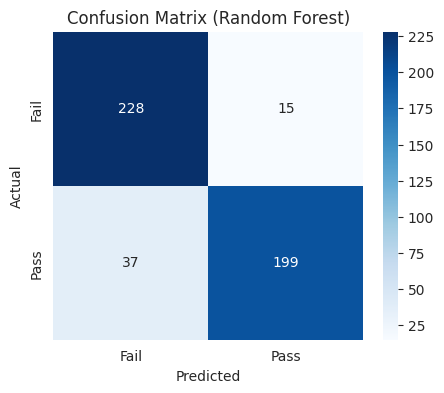

In [15]:
cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Fail', 'Pass'], yticklabels=['Fail', 'Pass'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Random Forest)')
plt.show()


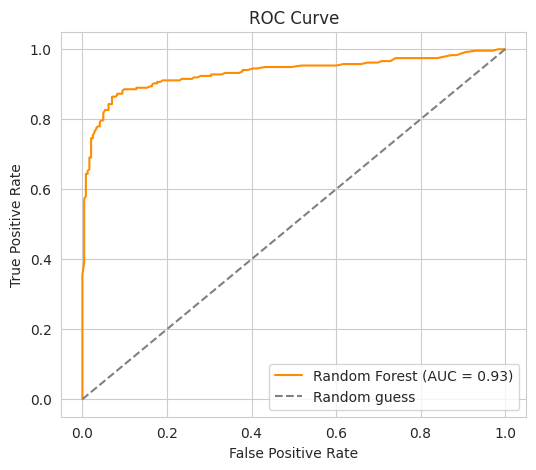

In [16]:
fpr, tpr, _ = roc_curve(y_test, y_prob_rf)
auc = roc_auc_score(y_test, y_prob_rf)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'Random Forest (AUC = {auc:.2f})', color='darkorange')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()


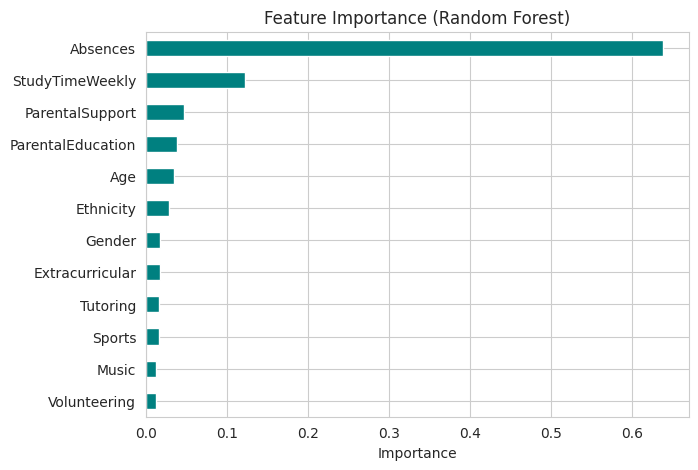

In [17]:
importances = pd.Series(rf_model.feature_importances_, index=features).sort_values()

plt.figure(figsize=(7, 5))
importances.plot(kind='barh', color='teal')
plt.title('Feature Importance (Random Forest)')
plt.xlabel('Importance')
plt.show()


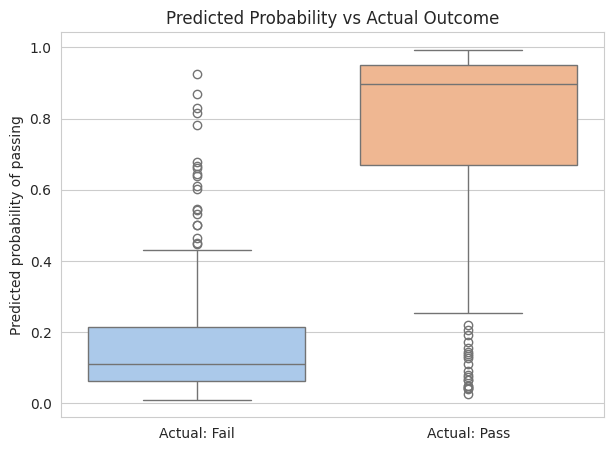

In [18]:
plt.figure(figsize=(7, 5))
sns.boxplot(x=y_test.values, y=y_prob_rf, hue=y_test.values, palette='pastel', legend=False)
plt.xticks([0, 1], ['Actual: Fail', 'Actual: Pass'])
plt.ylabel('Predicted probability of passing')
plt.title('Predicted Probability vs Actual Outcome')
plt.show()


## Summary

- Loaded and cleaned the real student performance dataset (2,392 students, no missing values or duplicates found).
- Defined a binary `success` target from `GradeClass` (Pass = grades A–D, Fail = grade F), excluding `GPA`/`GradeClass` from the features to avoid label leakage.
- Trained and compared Logistic Regression and Random Forest classifiers.
- **`Absences` is by far the strongest predictor of failure**, followed by `StudyTimeWeekly` and `ParentalSupport`.
- Random Forest reached ~89% accuracy and an AUC of ~0.93 on held-out data.
- The trained model can predict pass/fail for any new student profile — see Section 7.

**Next steps you could try:** predict the full 5-class `GradeClass` (A–F) instead of binary pass/fail, tune hyperparameters with `GridSearchCV`, or try `GradientBoostingClassifier` / `XGBoost`.